In [ ]:
""" !unzip "drive/MyDrive/Dog Vision/dog-breed-identification.zip" -d "drive/MyDrive/Dog Vision/" """

' !unzip "drive/MyDrive/Dog Vision/dog-breed-identification.zip" -d "drive/MyDrive/Dog Vision/" '

# End-to-end multi-class dog breed classification

This notebook builts an end-to-end multi-class image classifier using tensorflow 2.0 and tensorflow hub

## 1. Problem
Identifying the breed of a dog given an image of a dog.

when I am sitting at the cafe and take a picture of it, I want to know what breed of a dog it is.

## 2. Data

The data is from kaggle's data

## 3. Evaluation

we are going to use multi-class log loss

The evaluation is a file with prediction probabilities for each dog breed of each test image.

## 4. Features

some info about the data:
* we are dealing with images (unstructured data) so it's probably best we use deep learning/transfer learning.
* There are 120 breeds of dogs (This means there are 120 different classes)
* There are around 10 000+ images in the training set (These have labels)
* There are around 10 000+ images in the test set (These have no labels, because we will be predicting them)

### Get our workspace ready

* Import Tensorflow 2.x (already have)
* Import Tensorflow Hub
* Make sure we are using a GPU

In [ ]:
# Import Tensorflow into colab and necessary tools
import tensorflow_hub as hub
import tensorflow as tf
print("TF version", tf.__version__)
print("TF HUb version", hub.__version__)

# Check for GPU availability
print('GPU',"available(YESSS!!!!)" if tf.config.list_physical_devices("GPU") else "not available")


TF version 2.19.0
TF HUb version 0.16.1
GPU available(YESSS!!!!)


## Getting our data ready (turning them into tensors)

with all ML models we want our data to be in numerical form

In [ ]:
# checkout the labels of our data
import pandas as pd
labels_csv = pd.read_csv('drive/MyDrive/Dog Vision/labels.csv')
print(labels_csv.describe())
print(labels_csv.head())

                                      id               breed
count                              10222               10222
unique                             10222                 120
top     fff43b07992508bc822f33d8ffd902ae  scottish_deerhound
freq                                   1                 126
                                 id             breed
0  000bec180eb18c7604dcecc8fe0dba07       boston_bull
1  001513dfcb2ffafc82cccf4d8bbaba97             dingo
2  001cdf01b096e06d78e9e5112d419397          pekinese
3  00214f311d5d2247d5dfe4fe24b2303d          bluetick
4  0021f9ceb3235effd7fcde7f7538ed62  golden_retriever


In [ ]:
# How many images are there of each breed
labels_csv['breed'].value_counts()

,count
breed,
scottish_deerhound,126
maltese_dog,117
afghan_hound,116
entlebucher,115
bernese_mountain_dog,114
...,...
golden_retriever,67
komondor,67
brabancon_griffon,67


<Axes: xlabel='breed'>

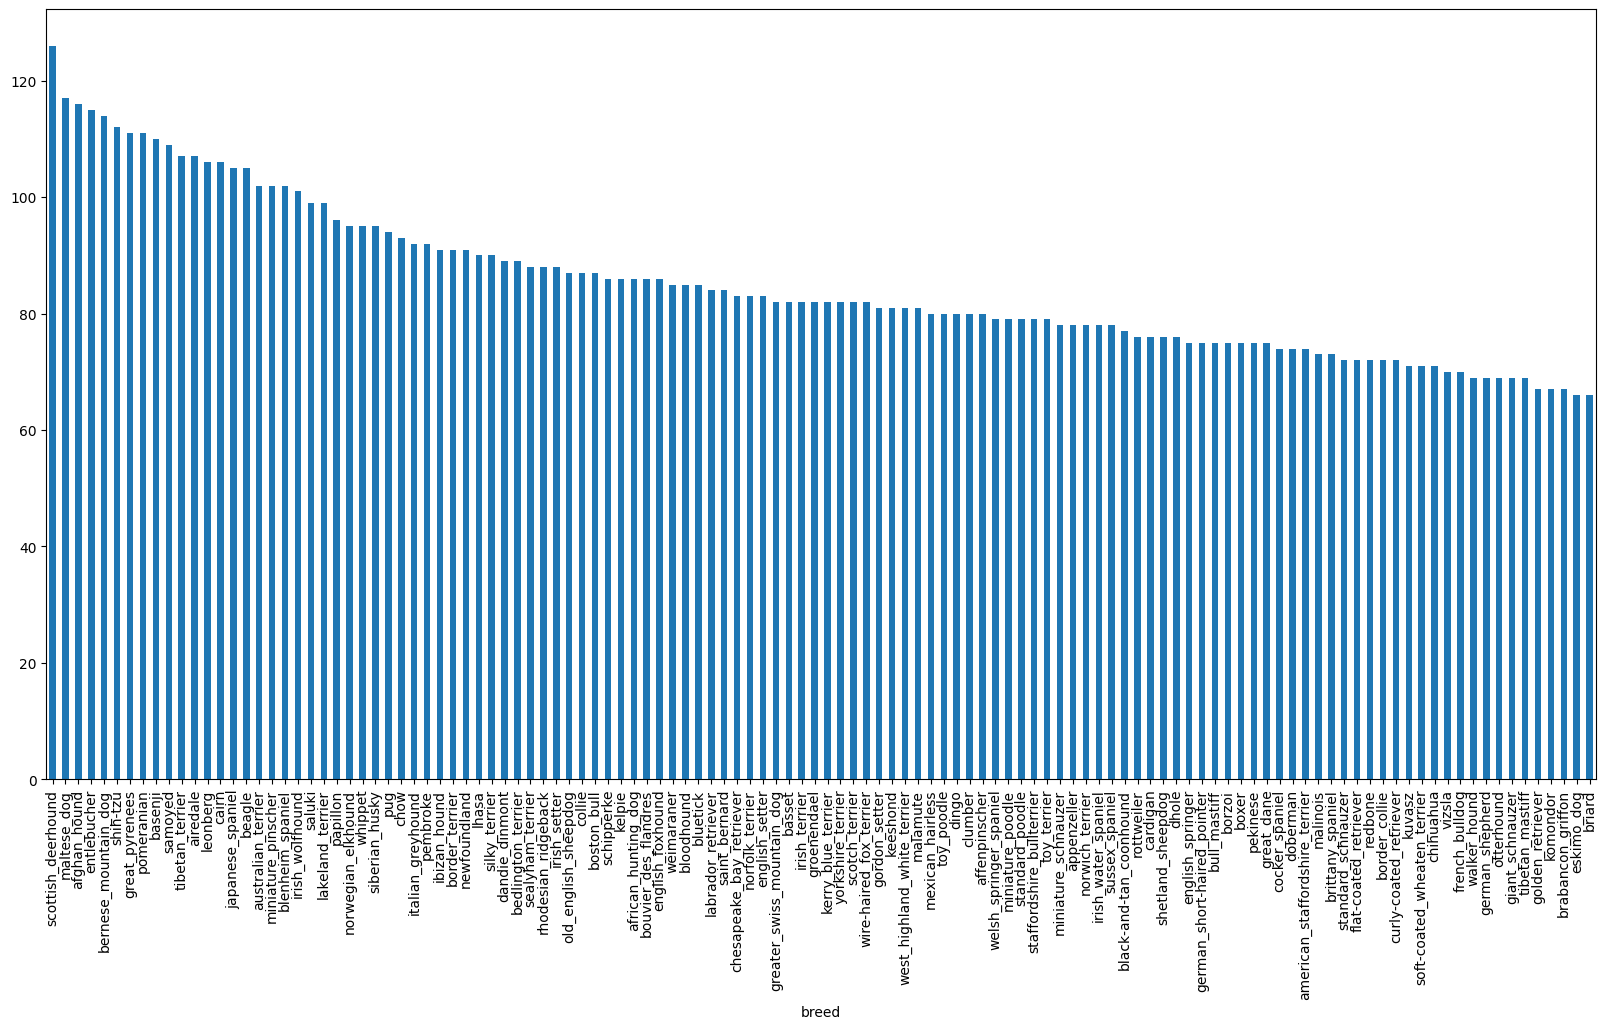

In [ ]:
labels_csv['breed'].value_counts().plot.bar(figsize = (20,10))

In [ ]:
labels_csv['breed'].value_counts().mean()

np.float64(85.18333333333334)

In [ ]:
labels_csv['breed'].value_counts().median()

82.0

In [ ]:
labels_csv['breed'].value_counts().min()

66

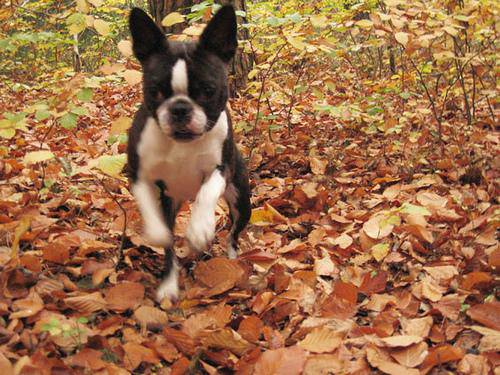

In [ ]:
# Let's view an image
from IPython.display import Image
Image("drive/MyDrive/Dog Vision/train/000bec180eb18c7604dcecc8fe0dba07.jpg")

### Getting images and their labes

let's get a list of all our image file path-names

In [ ]:
# Create path-names from image ID's
filename = ["drive/MyDrive/Dog Vision/train/" + fname + ".jpg" for fname in labels_csv['id']]

# check the first 10
filename[:10]

['drive/MyDrive/Dog Vision/train/000bec180eb18c7604dcecc8fe0dba07.jpg',
 'drive/MyDrive/Dog Vision/train/001513dfcb2ffafc82cccf4d8bbaba97.jpg',
 'drive/MyDrive/Dog Vision/train/001cdf01b096e06d78e9e5112d419397.jpg',
 'drive/MyDrive/Dog Vision/train/00214f311d5d2247d5dfe4fe24b2303d.jpg',
 'drive/MyDrive/Dog Vision/train/0021f9ceb3235effd7fcde7f7538ed62.jpg',
 'drive/MyDrive/Dog Vision/train/002211c81b498ef88e1b40b9abf84e1d.jpg',
 'drive/MyDrive/Dog Vision/train/00290d3e1fdd27226ba27a8ce248ce85.jpg',
 'drive/MyDrive/Dog Vision/train/002a283a315af96eaea0e28e7163b21b.jpg',
 'drive/MyDrive/Dog Vision/train/003df8b8a8b05244b1d920bb6cf451f9.jpg',
 'drive/MyDrive/Dog Vision/train/0042188c895a2f14ef64a918ed9c7b64.jpg']

In [ ]:
# Check whether number of filenames match number of actual image files
import os
if len(os.listdir('drive/MyDrive/Dog Vision/train/')) == len(filename):
  print('Filenames match actual amount of files!!! Proceed.')
else:
  print("Filenames do not match actual amount of files!!! do not proceed")

Filenames match actual amount of files!!! Proceed.


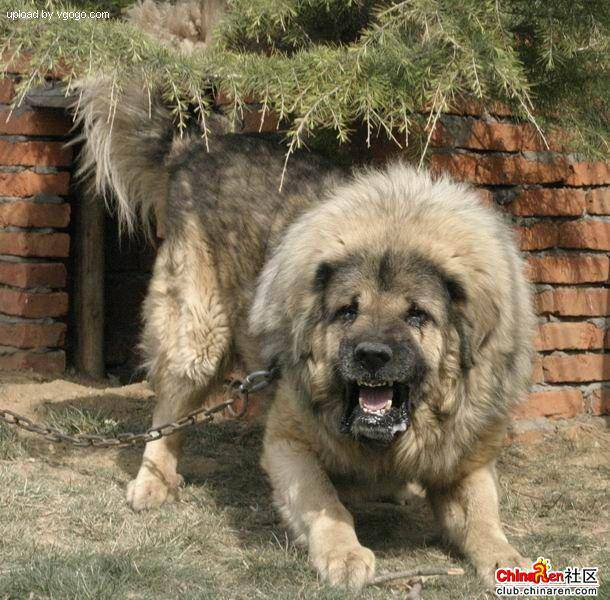

In [ ]:
# One more check
Image(filename[9000])

In [ ]:
labels_csv['breed'][9000]

'tibetan_mastiff'

Since we have now got our train image filepaths in a list, let us prepare labels

In [ ]:
import numpy as np
labels = labels_csv['breed'].to_numpy()
labels

array(['boston_bull', 'dingo', 'pekinese', ..., 'airedale',
       'miniature_pinscher', 'chesapeake_bay_retriever'], dtype=object)

In [ ]:
len(labels)

10222

In [ ]:
# Check if number of labels match the number of filenames
if len(labels) == len(filename):
  print("No of labels match no of filename")
else:
  print('They do not match')

No of labels match no of filename


In [ ]:
# Find the unique label values
unique_breeds = np.unique(labels)
len(unique_breeds)

120

In [ ]:
# Turn a single label into an array of booleans
print(labels[0])
labels[0] == unique_breeds

boston_bull


array([False, False, False, False, False, False, False, False, False,
       False, False, False, False, False, False, False, False, False,
       False,  True, False, False, False, False, False, False, False,
       False, False, False, False, False, False, False, False, False,
       False, False, False, False, False, False, False, False, False,
       False, False, False, False, False, False, False, False, False,
       False, False, False, False, False, False, False, False, False,
       False, False, False, False, False, False, False, False, False,
       False, False, False, False, False, False, False, False, False,
       False, False, False, False, False, False, False, False, False,
       False, False, False, False, False, False, False, False, False,
       False, False, False, False, False, False, False, False, False,
       False, False, False, False, False, False, False, False, False,
       False, False, False])

In [ ]:
# Turn evry label into Boolean array
boolean_labels = [label == unique_breeds for label in labels]
boolean_labels[:2]

[array([False, False, False, False, False, False, False, False, False,
        False, False, False, False, False, False, False, False, False,
        False,  True, False, False, False, False, False, False, False,
        False, False, False, False, False, False, False, False, False,
        False, False, False, False, False, False, False, False, False,
        False, False, False, False, False, False, False, False, False,
        False, False, False, False, False, False, False, False, False,
        False, False, False, False, False, False, False, False, False,
        False, False, False, False, False, False, False, False, False,
        False, False, False, False, False, False, False, False, False,
        False, False, False, False, False, False, False, False, False,
        False, False, False, False, False, False, False, False, False,
        False, False, False, False, False, False, False, False, False,
        False, False, False]),
 array([False, False, False, False, False, Fal

In [ ]:
len(boolean_labels)

10222

In [ ]:
# Example turning boolena array into integers
print(labels[0]) # Original label
print(np.where(unique_breeds == labels[0])) # Index where label occurs
print(boolean_labels[0].argmax()) # Index where label occurs in boolean array
print(boolean_labels[0].astype(int)) # There will be a 1 where the sample label occurs

boston_bull
(array([19]),)
19
[0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 1 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 0 0 0 0 0 0 0 0 0]


### Creating our own validation set

Since the data from kaggle does not provide valid set we are going to create our own

In [ ]:
x = filename
y = boolean_labels

we are going to start off experimenting with ~ 1000 images and increase as needed

In [ ]:
# Set number of images to use for experimenting
NUM_IMAGES = 1000 #@param{type:"slider", min:1000, max:10000, step:1000}

In [ ]:
# Let us split our data into train and validation sets
from sklearn.model_selection import  train_test_split

# Split them into training and validation of total size NUM_IMAGES
x_train,x_val,y_train,y_val = train_test_split(x[:NUM_IMAGES],
                                               y[:NUM_IMAGES],
                                               test_size = 0.2,
                                               random_state = 42)

len(x_train), len(x_val), len(y_train), len(y_val)

(800, 200, 800, 200)

In [ ]:
x_train[:2], y_train[:2]

(['drive/MyDrive/Dog Vision/train/00bee065dcec471f26394855c5c2f3de.jpg',
  'drive/MyDrive/Dog Vision/train/0d2f9e12a2611d911d91a339074c8154.jpg'],
 [array([False, False, False, False, False, False, False, False, False,
         False, False, False, False, False, False, False, False, False,
         False, False, False, False, False, False, False, False,  True,
         False, False, False, False, False, False, False, False, False,
         False, False, False, False, False, False, False, False, False,
         False, False, False, False, False, False, False, False, False,
         False, False, False, False, False, False, False, False, False,
         False, False, False, False, False, False, False, False, False,
         False, False, False, False, False, False, False, False, False,
         False, False, False, False, False, False, False, False, False,
         False, False, False, False, False, False, False, False, False,
         False, False, False, False, False, False, False, Fal

## Preprocessing images (turning images into Tensors)

To preprocess images into tensors we are going to write a function which does a few things
* Take an image filapath as input
* Use Tensorflow to read the file and save ot to a variable, 'image'
* Turn our 'image' (a Jpg) into tensors
* Resize the  'image' to be a shape of (224,224)
* Return the modified 'image'

Before we do, let us see what importing an image looks like

In [ ]:
# Convert an image to numpy array
from matplotlib.pyplot import imread
image = imread(filename[42])
image.shape

(257, 350, 3)

In [ ]:
image.max(),image.min()

(np.uint8(255), np.uint8(0))

In [ ]:
tf.constant(image)[:2]

<tf.Tensor: shape=(2, 350, 3), dtype=uint8, numpy=
array([[[ 89, 137,  89],
        [ 76, 124,  76],
        [ 63, 111,  61],
        ...,
        [ 77, 133,  86],
        [ 76, 134,  86],
        [ 76, 134,  86]],

       [[ 72, 119,  75],
        [ 67, 114,  68],
        [ 63, 110,  64],
        ...,
        [ 75, 131,  84],
        [ 74, 132,  84],
        [ 74, 132,  84]]], dtype=uint8)>

Now we have seen what an image looks like as a tensor, let's make a function

To preprocess images into tensors we are going to write a function which does a few things
* Take an image filapath as input
* Use Tensorflow to read the file and save ot to a variable, 'image'
* Turn our 'image' (a Jpg) into tensors
* Normalize our image (convert the channel values from 0-255 to 0-1 values)
* Resize the  'image' to be a shape of (224,224)
* Return the modified 'image'

Before we do, let us see what importing an image looks like

In [ ]:
# Define image size
IMG_SIZE = 224

# Create a function for preprocessing images
def process_image(image_path, img_size = IMG_SIZE):
  """
  Takes an image filepath and turn the image into a tensor
  """
  # Read an image file
  image = tf.io.read_file(image_path)
  # Turn the jpeg image into numerical Tensor with 3 colour channels (RGB)
  image = tf.image.decode_jpeg(image, channels=3)
  # Convert the colour channel values form 0-255 to 0-1 values
  image = tf.image.convert_image_dtype(image, tf.float32)
  # Resize the image to our desrired value (224,224)
  image = tf.image.resize(image, size=[IMG_SIZE,IMG_SIZE])

  return image



## Turning our data into batches

Why turn our data into batches?

Let's say you are trying to process 10000+ images in one... they all might not fit into memory

So that's why we do 32 (batch size) images at a time

In order to use tensorflow effectively, we need our data in the form of Tensor tuples which looks like this (image, label)

In [ ]:
# Create a simple function to return a tuple (image, label)
def get_image_label(image_path,label):
  """
  Takes an image file path name and the associated label,
  processes the image and returns a tuple of (image,label).
  """

  image = process_image(image_path)
  return image,label

In [ ]:
# Demo of the above
(process_image(x[42]), tf.constant(y[42]))

(<tf.Tensor: shape=(224, 224, 3), dtype=float32, numpy=
 array([[[0.3264178 , 0.5222886 , 0.3232816 ],
         [0.2537167 , 0.44366494, 0.24117757],
         [0.25699762, 0.4467087 , 0.23893751],
         ...,
         [0.29325107, 0.5189916 , 0.3215547 ],
         [0.29721776, 0.52466875, 0.33030328],
         [0.2948505 , 0.5223015 , 0.33406618]],
 
        [[0.25903144, 0.4537807 , 0.27294815],
         [0.24375686, 0.4407019 , 0.2554778 ],
         [0.2838985 , 0.47213382, 0.28298813],
         ...,
         [0.2785345 , 0.5027992 , 0.31004712],
         [0.28428748, 0.5108719 , 0.32523635],
         [0.28821915, 0.5148036 , 0.32916805]],
 
        [[0.20941195, 0.40692952, 0.25792548],
         [0.24045378, 0.43900946, 0.2868911 ],
         [0.29001117, 0.47937486, 0.32247734],
         ...,
         [0.26074055, 0.48414773, 0.30125174],
         [0.27101526, 0.49454468, 0.32096273],
         [0.27939945, 0.5029289 , 0.32934693]],
 
        ...,
 
        [[0.00634795, 0.03442048

Now we have got a way to turn our data into tuples of Tensors in the form '(image, label)', let us make a function to turn all of our data(x and y) into batches

In [ ]:
# Define the batch size, 32 is a good start
BATCH_SIZE = 32

# Create a function to turn data into batches
def create_data_batches(x,y=None, batch_size = BATCH_SIZE, valid_data = False, test_data = False):
  """
  Create batches of data out of image (x) and label (y) pairs
  Shuffles the data if it is training data
  Also accepts test data as input (no labels)
  """
  # if the data is a test data, we probably don't have labels
  if test_data:
    print('Creating test data batches...')
    data = tf.data.Dataset.from_tensor_slices((tf.constant(x))) # only filepaths (no labels)
    data_batch = data.map(process_image).batch(BATCH_SIZE)
    return data_batch

  # If the data is a valid dataset, we do not need to shuffle it
  elif valid_data:
    print('Creating validation data batches...')
    data = tf.data.Dataset.from_tensor_slices((tf.constant(x), # filepaths
                                               tf.constant(y))) # labels
    data_batch = data.map(get_image_label).batch(BATCH_SIZE)
    return data_batch

  else:
    print('Creating training data batches...')
    # Turn filepaths and labels into tensors
    data = tf.data.Dataset.from_tensor_slices((tf.constant(x), # filepaths
                                               tf.constant(y))) # labels
    # Shuffling pathnames and labels before mapping image processor function is faster than shuffling images
    data = data.shuffle(buffer_size = len(x))

    # Create (image,label) tuples (this also turns the image path into preprocessed image)
    data = data.map(get_image_label)

    # Turn the training data into batches
    data_batch = data.batch(BATCH_SIZE)

  return data_batch


In [ ]:
# Create training and validation data batches
train_data = create_data_batches(x_train,y_train)
val_data = create_data_batches(x_val,y_val, valid_data=True)

Creating training data batches...
Creating validation data batches...


In [ ]:
train_data.element_spec, val_data.element_spec

((TensorSpec(shape=(None, 224, 224, 3), dtype=tf.float32, name=None),
  TensorSpec(shape=(None, 120), dtype=tf.bool, name=None)),
 (TensorSpec(shape=(None, 224, 224, 3), dtype=tf.float32, name=None),
  TensorSpec(shape=(None, 120), dtype=tf.bool, name=None)))

## Visualize Data Batches

Our data is now in batches, this can be hard to comprehend, so let us visualize them

In [ ]:
import matplotlib.pyplot as plt

# Create a function for viewing images in a data batch.
def show_25_images(images,labels):
  """
  Displays a plot of 25 images and their labels from a data batch
  """
  # Setup the figure
  plt.figure(figsize=(10,10))
  # Loop through 25 (for displaying 25 images)
  for i in range(25):
    # Create subplots (5 rows, 5 columns)
    ax = plt.subplot(5,5, i+1)
    # Display an image
    plt.imshow(images[i])
    # Add the image label as the title
    plt.title(unique_breeds[labels[i].argmax()])
    # Turn the grid lines off
    plt.axis('off')

In [ ]:
train_images, train_labels = next(train_data.as_numpy_iterator())
len(train_images), len(train_labels)

(32, 32)

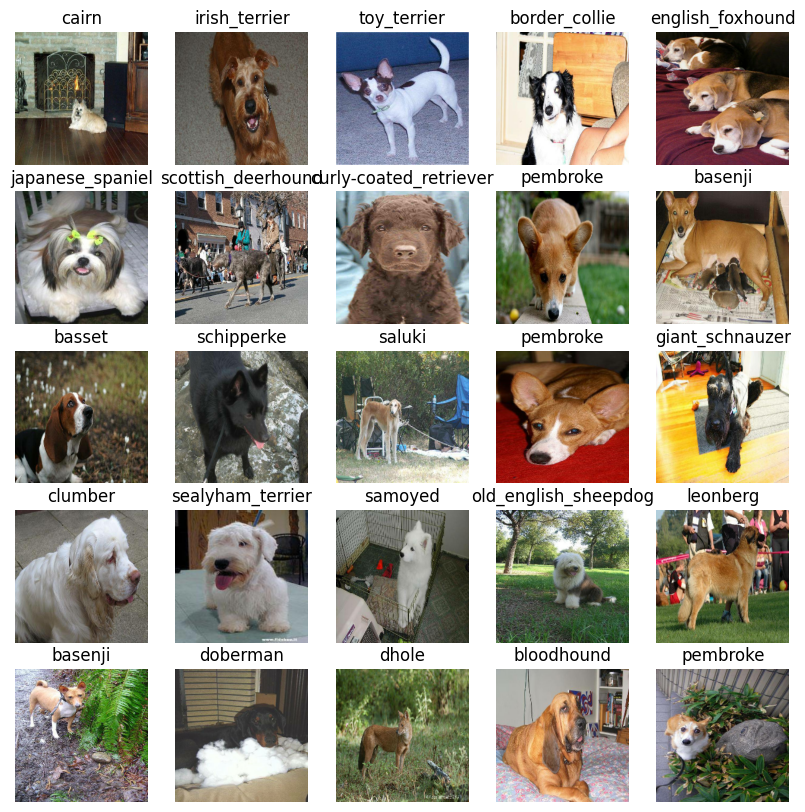

In [ ]:
# Now let us visulize the data in a training batch
show_25_images(train_images, train_labels)

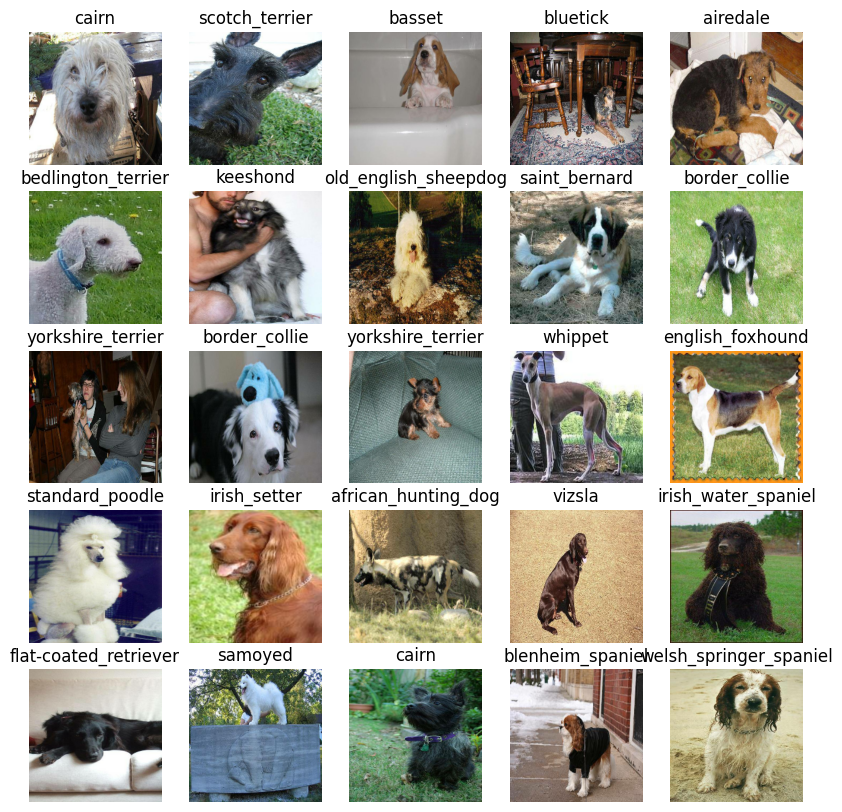

In [ ]:
# Now let us visualize the validation data into batches
val_images, val_labels = next(val_data.as_numpy_iterator())
show_25_images(val_images,val_labels)

## Building a model

Before we build a model, there are a few things we need to define:
* The input shape (our image shape, in the form of Tensors) to our model.
* The Output shape (image labels, in the form of Tensors) of our model.
* The URL of the model we want to use from tensorflow hub

In [ ]:
# Setup input shape to the model
INPUT_SHAPE = [None, IMG_SIZE, IMG_SIZE, 3] # batch, height, width, colour channels

# Setup the output shape of our model
OUTPUT_SHAPE = len(unique_breeds)

# Setup model URL from Tensorflow Hub
MODEL_URL = "https://tfhub.dev/google/imagenet/mobilenet_v2_130_224/classification/4"

from tensorflow.python.data.ops.options import model_pb2
Now we have got our inputs, outputs and model ready to go.
Let us put them together into a keras deep learning model_pb2

Knowing this, let's create a function which:
* Takes the input shape, output shape and model we've choses as parameters.
* Defines the layers in a keras model in sequential form (do this first, then this, then that).
* Compiles the model (says it should be evaluated and improved).
* Builds the model (tells the model the input shape it will be getting).
* Returns the model.

All this steps can be found in Tensorflow hub

In [ ]:
import tensorflow as tf
import tf_keras as keras

# Create a function which builds a keras model
def create_model(input_shape = INPUT_SHAPE, output_shape = OUTPUT_SHAPE, model_url = MODEL_URL):
  print('Building model with:', MODEL_URL)

  # Setupe the model layers
  model = keras.Sequential([
      hub.KerasLayer(MODEL_URL), # Layer 1 (input layer)
      keras.layers.Dense(units = OUTPUT_SHAPE,
                            activation = 'softmax') # Layer 2 (output layer)
  ])

  # Compile the model
  model.compile(
      loss = keras.losses.CategoricalCrossentropy(),
      optimizer = keras.optimizers.Adam(),
      metrics = ['accuracy']
  )

  # Build the model
  model.build(INPUT_SHAPE)

  return model

In [ ]:
model = create_model()
model.summary()

Building model with: https://tfhub.dev/google/imagenet/mobilenet_v2_130_224/classification/4
Model: "sequential"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 keras_layer (KerasLayer)    (None, 1001)              5432713   
                                                                 
 dense (Dense)               (None, 120)               120240    
                                                                 
Total params: 5552953 (21.18 MB)
Trainable params: 120240 (469.69 KB)
Non-trainable params: 5432713 (20.72 MB)
_________________________________________________________________


## Creating callbacks

callbacks are helper functions a model can use during training to do such things as save its progress, check its progress or stop training early if a model stops improving.

wew will create two callbacks
* One for Tensorboard which helps track our model's progress
* another for early stopping which prevents our model from training for too long.

### Tensorboard Callback

To setup a tensorboard callback, we need to do 3 things:
1. Load the Tensorboard notebook extension
2. Create a TensorBoard callback which is able to save logs to a directory and pass it to our model 'fit()' function.
3. Visualize our model's training logs with the "%tensorboard" magic function (we will do this afyer model training)


In [ ]:
# Load Tensorboard notebook extension
%load_ext tensorboard

In [ ]:
import datetime

# Create a function to build a Tensorboard callback
def create_tensorboard_callback():
  # Create a log directory for storing TensorBoard logs
  logdir = os.path.join("drive/MyDrive/Dog Vision/logs",
                        # Make it so the logs get tracked whenever we run an experiment
                        datetime.datetime.now().strftime("%Y%m%d-%H%M%S"))
  return keras.callbacks.TensorBoard(logdir)

### Early stopping callback

early stopping helps stop our model from overfitting by stopping training if a certain if a certain evaluation metric stops

In [ ]:
# Create early stopping callback
early_stopping = keras.callbacks.EarlyStopping(monitor = 'val_accuracy',
                                               patience = 3)

## Training a  model (on a subset of data)

Our first model is only going to train on a 1000 images, to make sure everything is working

In [ ]:
NUM_EPOCHS = 100 #@param {type: 'slider', min:10, max:100, step:10}


In [ ]:
# Check to make sure we are still using a GPU
print('GPU',"available(YESSS!!!!)" if tf.config.list_physical_devices("GPU") else "not available")


GPU available(YESSS!!!!)


Let's create a function which trains a model.

* Create a model using 'create_model'
* Setup a Tensorboard callback using 'create_tensorboard_callback'
* call the 'fit()'function on our model passing it the training data, validation data, Number of epochs to train for (NUM_EPOCHS) and the callbacks we'd like to use
* Return model

In [ ]:
# Build a function to train and return a trained model
def train_model():
  """
  Trains a given model and returns the trained version
  """
  # Create a model
  model = create_model()

  # Create new Tensorboard session everytime we train a model
  tensorboard = create_tensorboard_callback()

  # Fit the model to the data passing it the callbacks we created
  model.fit(x = train_data,
            epochs = NUM_EPOCHS,
            validation_data = val_data,
            validation_freq = 1, # Check validation metrics for every epoch
            callbacks = [tensorboard, early_stopping])
  return model

In [ ]:
# Fit the model to the data
model = train_model()

Building model with: https://tfhub.dev/google/imagenet/mobilenet_v2_130_224/classification/4
Epoch 1/100


KeyboardInterrupt: 

**Question:** Our model is overfitting because it is performing far better on the training dataset than the validation dataset, what are some ways to prevent model overfitting in deep learning neural networks?


**NOTE:** Overfitting is a good thing because it means our model is learning!!!

### Checking the Tensorboard logs

The Tensorboard magic function '%tensorboard' will access the logs directory we created eariler and visualize its contents

In [ ]:
%tensorboard --logdir drive/MyDrive/Dog\ Vision/logs

### Making and evaluating predictions using a trained model

In [ ]:
val_data

In [ ]:
# Make prediction on the validation data (not used to train on)

predictions = model.predict(val_data, verbose = 1)
predictions

7/7 [==============================] - 2s 174ms/step


array([[0.00898743, 0.05055726, 0.0198949 , ..., 0.00087964, 0.00647074,
        0.00588829],
       [0.00186854, 0.00961944, 0.00051143, ..., 0.0013184 , 0.00883952,
        0.02092668],
       [0.01846617, 0.0009591 , 0.00092367, ..., 0.00274206, 0.00982443,
        0.01726232],
       ...,
       [0.00658218, 0.00172106, 0.00199024, ..., 0.01487629, 0.00221152,
        0.00514961],
       [0.02673592, 0.07061991, 0.00804623, ..., 0.01258203, 0.01106827,
        0.00363245],
       [0.0060585 , 0.00044034, 0.00120818, ..., 0.00570311, 0.01559785,
        0.00195165]], dtype=float32)

In [ ]:
predictions.shape

(200, 120)

In [ ]:
# First prediction
index = 42
print(predictions[index])
print(f"Max value (probability of prediction): {np.max(predictions[index])}")
print(f"Sum: {np.sum(predictions[index])}")
print(f"Max index: {np.argmax(predictions[index])}")
print(f"Predicted label: {unique_breeds[np.argmax(predictions[index])]}")

[1.6458273e-02 4.7901021e-03 2.7398595e-03 1.9542240e-03 2.0549360e-01
 4.6035578e-03 1.2320118e-03 3.4897663e-03 1.7785013e-03 6.0141631e-03
 3.5587903e-02 4.3459414e-03 9.7107550e-04 1.1043382e-03 3.0176307e-03
 1.9862636e-03 8.2179215e-03 1.7585206e-03 2.4835290e-03 1.7450154e-03
 6.4470642e-03 2.7226906e-03 4.2222343e-02 1.9431034e-02 5.3518321e-03
 3.6721113e-03 8.6330548e-03 6.8442035e-03 1.2099496e-03 2.1016588e-03
 9.3512172e-03 2.5784713e-03 3.7188299e-03 5.7846389e-04 4.7290321e-03
 4.2894576e-03 1.6900523e-03 2.8319224e-03 1.3798694e-03 2.0326519e-02
 2.2254654e-03 1.9391463e-03 3.8479394e-03 1.3497403e-03 1.8951135e-03
 9.0296671e-04 3.8180992e-03 2.2930338e-03 1.4003172e-03 1.5156504e-03
 1.1103884e-03 2.3149261e-03 6.7845808e-04 9.3093456e-04 1.4575864e-02
 2.9679369e-03 1.0679300e-03 5.6704335e-02 2.0793313e-03 1.6273446e-03
 1.7062725e-02 1.2918620e-03 3.8508355e-04 1.8401567e-02 3.1684421e-04
 3.0745051e-03 3.7595723e-03 4.9673923e-04 1.2627337e-03 3.5384938e-03
 9.187

Having the above functionality is great but we want to be able to do it in scale

and it would be even better if we can visualize it

**NOTE** Predictions probabilities are also known as confidence intervals

In [ ]:
# Turn probabilities into their respective labels (easier to understand)
def get_pred_label(prediction_probabilities):
  """
  Turns an array of predictions into a label
  """
  return unique_breeds[np.argmax(prediction_probabilities)]

# Get a predicted label based on an array of prediction probabilities
pred_label = get_pred_label(predictions[81])
pred_label

'redbone'

Now since our validation is in a batch format, we will have to unbatchfy it to make predictions on the validation images and then compare those predictions to the validation labels (Truth labels)

In [ ]:
# Create a function to unbatch a batch dataset
def unbatchify(data):
  """
  Takes a batched dataset of (image,label) Tensors and returns seperate arrays of images and labels.
  """
  images = []
  labels = []
  # Loop through unbatched data
  for image, label in data.unbatch().as_numpy_iterator():
    images.append(image)
    labels.append(unique_breeds[np.argmax(label)])
  return images, labels

# Unbatchify the validation data
val_images, val_labels = unbatchify(val_data)
val_images[0], val_labels[0]

(array([[[0.29599646, 0.43284872, 0.3056691 ],
         [0.26635826, 0.32996926, 0.22846507],
         [0.31428418, 0.27701408, 0.22934894],
         ...,
         [0.77614343, 0.82320225, 0.8101595 ],
         [0.81291157, 0.8285351 , 0.8406944 ],
         [0.8209297 , 0.8263737 , 0.8423668 ]],
 
        [[0.2344871 , 0.31603682, 0.19543913],
         [0.3414841 , 0.36560842, 0.27241898],
         [0.45016077, 0.40117094, 0.33964607],
         ...,
         [0.7663987 , 0.8134138 , 0.81350833],
         [0.7304248 , 0.75012016, 0.76590735],
         [0.74518913, 0.76002574, 0.7830809 ]],
 
        [[0.30157745, 0.3082587 , 0.21018331],
         [0.2905954 , 0.27066195, 0.18401104],
         [0.4138316 , 0.36170745, 0.2964005 ],
         ...,
         [0.79871625, 0.8418535 , 0.8606443 ],
         [0.7957738 , 0.82859945, 0.8605655 ],
         [0.75181633, 0.77904975, 0.8155256 ]],
 
        ...,
 
        [[0.9746779 , 0.9878955 , 0.9342279 ],
         [0.99153054, 0.99772066, 0.94278

In [ ]:
get_pred_label(val_labels[0])

'affenpinscher'

Now we have ways to get:
* predictions labesl
* Validation labels (truth labels)
* Validation images

Lets us make some functions to maek these more visual

we will create a function which:
* Takes an array of prediction probabilities, an array of truth labels, and an array of images and integers.
* Convert the prediction probabilities to a predicted label.
* Plot the predicted label, its predicted probability, the truth label and the target image on a single plot.

In [ ]:
def plot_pred(prediction_probabilities, labels, images, n = 1):
  """
  View the prediction, ground truth and image for sample n
  """
  pred_prob, true_label, image = prediction_probabilities[n], labels[n], images[n]

  # Get the pred label
  pred_label = get_pred_label(pred_prob)

  # Plot the image and remove ticks
  plt.imshow(image)
  plt.xticks([])
  plt.yticks([])

  # Change the colour of the title depending on if the prediction is right or wrong
  if pred_label == true_label:
    color = 'green'
  else:
    color = 'red'


  # Change plot title to be predicted, probability of prediction and truth label
  plt.title("{} {:2.0f}% {}".format(pred_label,
                                    np.max(pred_prob)*100,
                                    true_label),
                                    color = color)
  pass

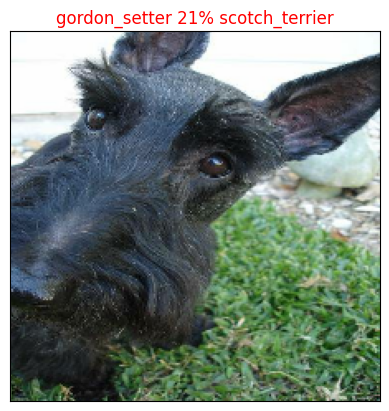

In [ ]:
plot_pred(prediction_probabilities=predictions,
          labels = val_labels,
          images = val_images)

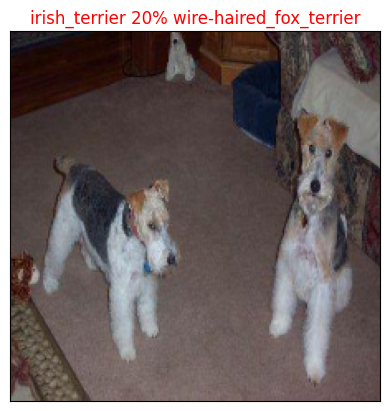

In [ ]:
plot_pred(prediction_probabilities=predictions,
          labels = val_labels,
          images = val_images,
          n = 41)

Now we have 1 function to visualize our model's top predictions, let's make another to view our model's top 10 predictions.

This function will:
* Take an input of prediction probabilities array and a ground truth and an integer.
* Find the prediction using 'get_pred_label()'
* Find the top 10:
  * Prediction probabilities indexes.
  * Prediction probabilities values.
  * Prediction labels.
* Plot the top 10 prediction probability values and labels, colouring the true labels green.

In [ ]:
def plot_pred_conf(prediction_probabilities, labels, n = 1):
  """
  Plus the top 10 highest prediction confidences along with the truth label for sample n.
  """
  pred_prob, true_label = prediction_probabilities[n], labels[n]

  # Get the predicted label
  pred_label = get_pred_label(pred_prob)

  # Find the top 10 prediction confidence indeces
  top_10_pred_indexes = pred_prob.argsort()[-10:][::-1]

  # Find the top 10 prediction confidences values
  top_10_pred_values = pred_prob[top_10_pred_indexes]

  # Find the top 10 prediction labels
  top_10_pred_labels = unique_breeds[top_10_pred_indexes]

  # Setup plot
  top_plot = plt.bar(np.arange(len(top_10_pred_labels)),
                     top_10_pred_values,
                     color = 'grey')
  plt.xticks(np.arange(len(top_10_pred_labels)),
             labels = top_10_pred_labels,
             rotation = 'vertical')

  # change the colour of true labels
  if np.isin(true_label, top_10_pred_labels):
    top_plot[np.argmax(top_10_pred_labels == true_label)].set_color('green')
  else:
    pass

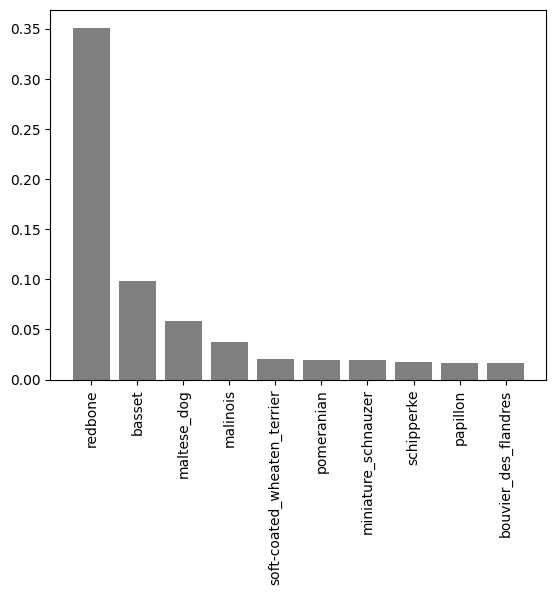

In [ ]:
plot_pred_conf(prediction_probabilities= predictions,
               labels = val_labels,
               n = 9)

Now we have some functions to help us visualize our predictions and evaluate our moidel, let us check out a few

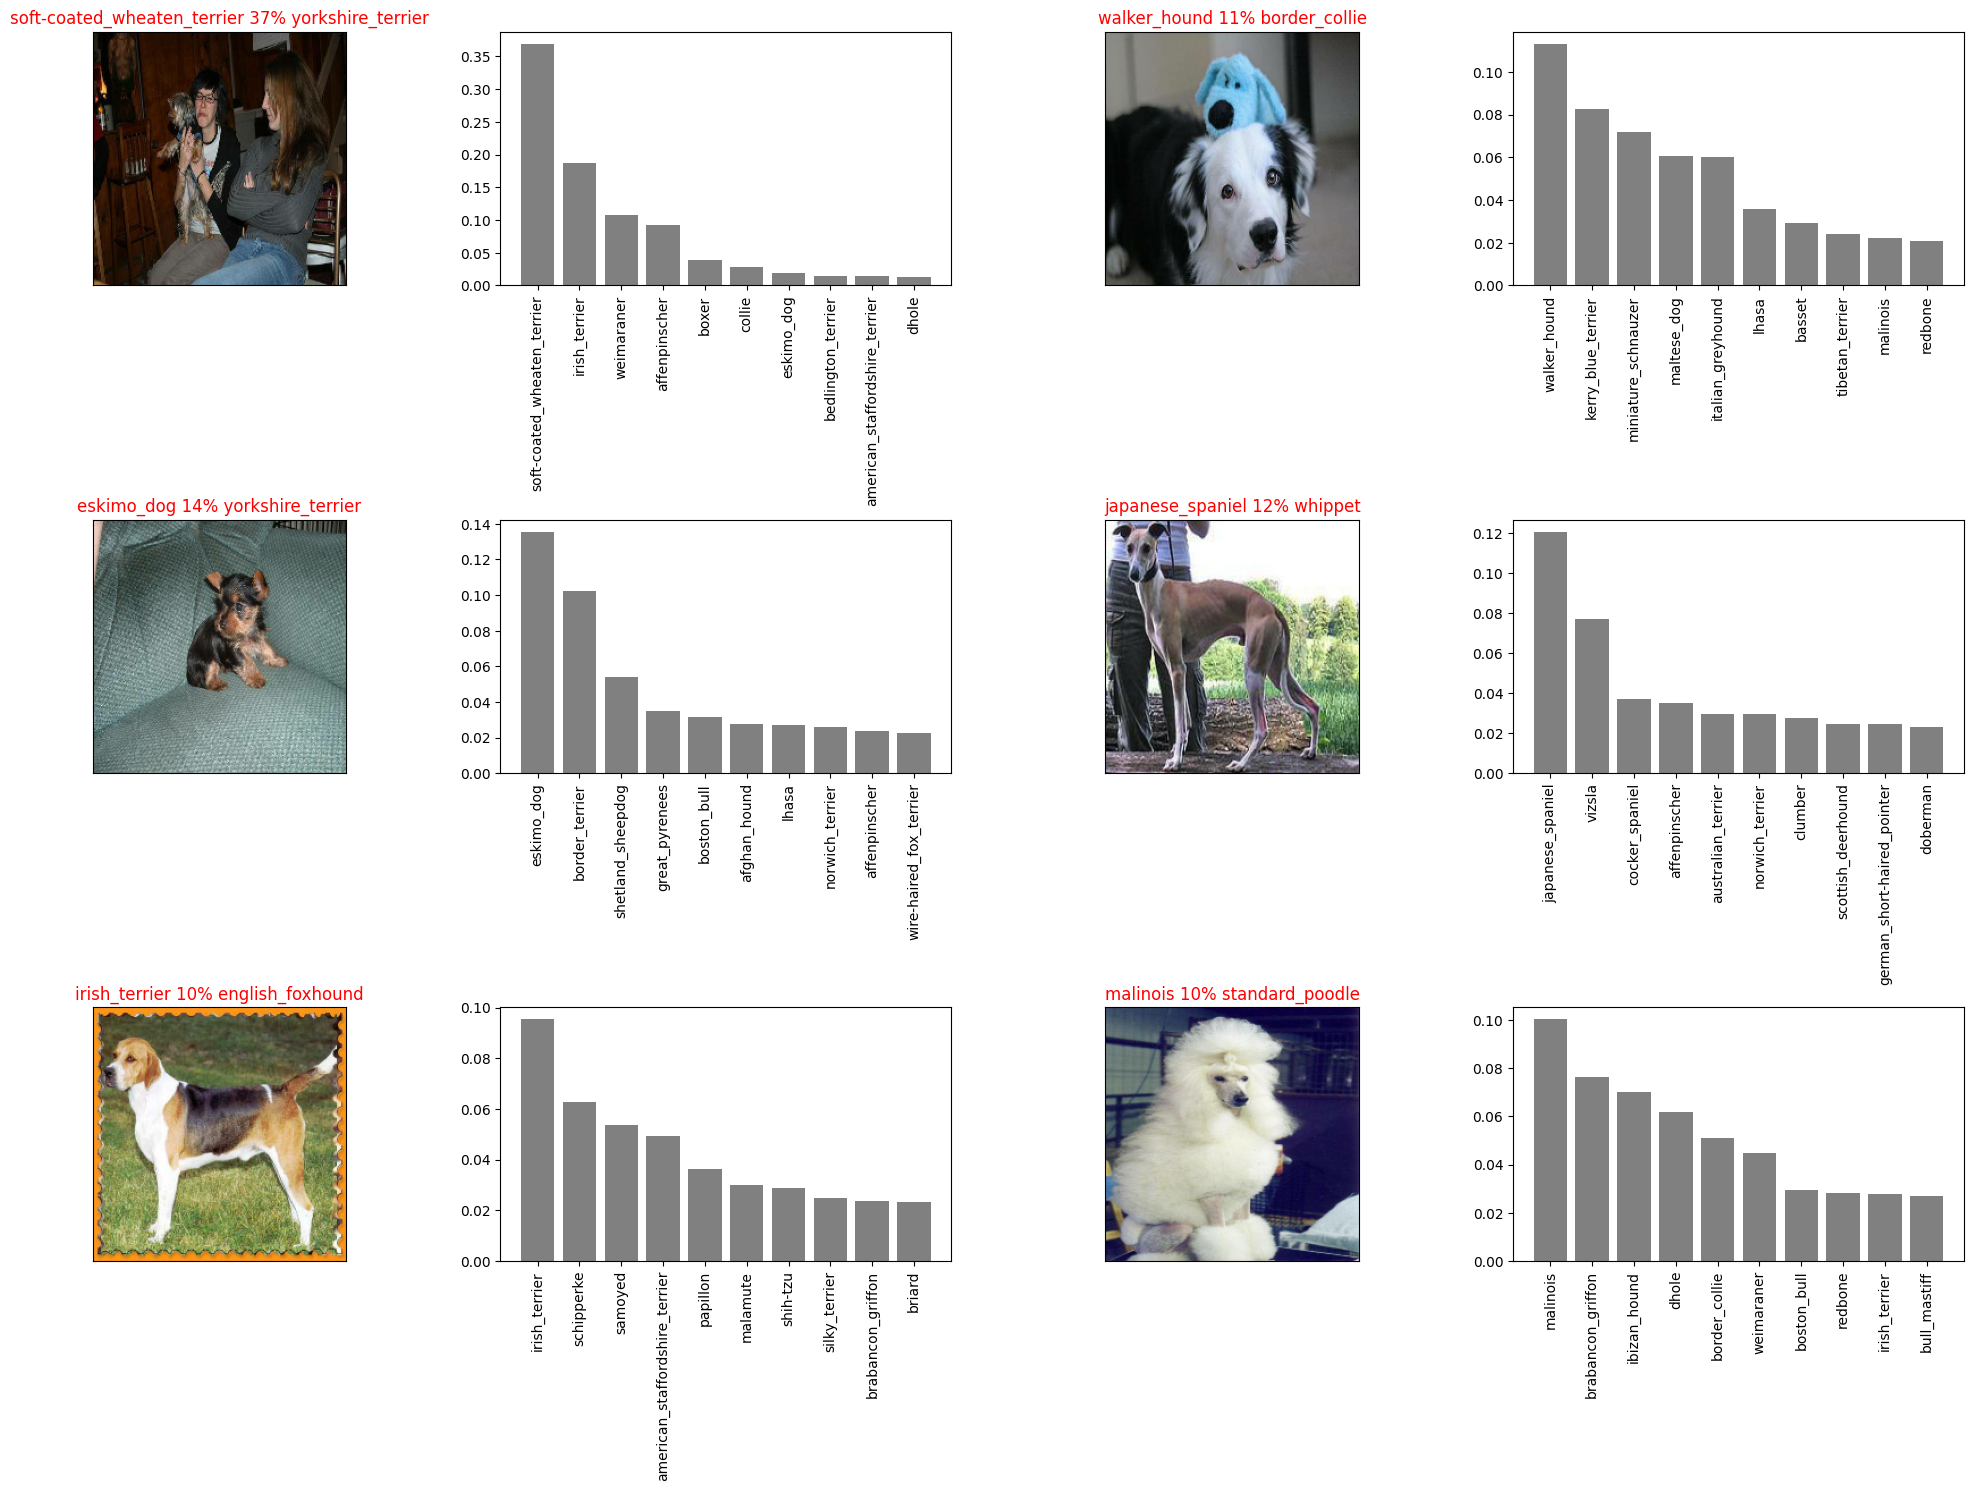

In [ ]:
# let's check out a few predictions and their different values
i_multiplier = 10
num_rows = 3
num_cols = 2
num_images = num_rows*num_cols
plt.figure(figsize = (10*num_cols, 5*num_rows))
for i in range(num_images):
  plt.subplot(num_rows, 2*num_cols, 2*i+1)
  plot_pred(prediction_probabilities=predictions,
            labels = val_labels,
            images = val_images,
            n = i + i_multiplier)
  plt.subplot(num_rows, 2*num_cols, 2*i+2)
  plot_pred_conf(prediction_probabilities = predictions,
                 labels = val_labels,
                 n = i + i_multiplier)
plt.tight_layout(h_pad = 1.0)
plt.show()

**Challenge** How would you create a confusion matrix with our models predictions and true labels?

### Saving and reloading a trained model

In [ ]:
# Create a functon to save a model
def save_model(model, suffix = None):
  """
  Saves a given model in a models directory and appends a suffix (string)
  """
  # Create a model directory pathname with current time
  modeldir = os.path.join("drive/MyDrive/Dog Vision/models",
                          datetime.datetime.now().strftime("%Y%m%d-%H%M%s"))
  model_path = modeldir + "-" + suffix + ".h5" # Save format of model
  print(f"Saving model to: {model_path}...")
  model.save(model_path)
  return model_path

In [ ]:
# Create a function to load a trained model
def load_model(model_path):
  """
  Loads a saved model from a specified path
  """
  print(f"Loading saved model from: {model_path}")
  model = keras.models.load_model(model_path,
                                  custom_objects = {"KerasLayer": hub.KerasLayer})
  return model

Now we have functions to save and load a trained model, let us make sure it works

In [ ]:
# Save our model trained on 1000 images
save_model(model, suffix = "1000-images-mobilenetv2-Adam")

In [ ]:
# Load a trained model
loaded_1000_image_model = load_model("drive/MyDrive/Dog Vision/models/20260217-19511771357881-1000-images-mobilenetv2-Adam.h5")

Loading saved model from: drive/MyDrive/Dog Vision/models/20260217-19511771357881-1000-images-mobilenetv2-Adam.h5


In [ ]:
# Evaluate the pre-saved model
model.evaluate(val_data)

In [ ]:
# Evaluated the loaded model
loaded_1000_image_model.evaluate(val_data)

## Training a big dog model (On Full data)

In [ ]:
len(x), len(y)

In [ ]:
# Create a data batch with the full data
full_data = create_data_batches(x,y)
full_data

Creating training data batches...


<_BatchDataset element_spec=(TensorSpec(shape=(None, 224, 224, 3), dtype=tf.float32, name=None), TensorSpec(shape=(None, 120), dtype=tf.bool, name=None))>

In [ ]:
# Create a model for full model
full_model = create_model()

Building model with: https://tfhub.dev/google/imagenet/mobilenet_v2_130_224/classification/4


In [ ]:
# Create full model callbacks
full_model_tensorboard = create_tensorboard_callback()
# No validation set when training on all the data,so we can't monitor validation accuracy
full_model_early_stopping = keras.callbacks.EarlyStopping(monitor = 'accuracy',
                                                          patience = 3)

**NOTE** Running the cell below will take a little while (maybe up tp 30 minutes for the first epoch) because the GPU we are using in the runtime has to load all of the images into memory.

In [ ]:
# Fit the full model to the full data
full_model.fit(x = full_data,
               epochs = NUM_EPOCHS,
               callbacks = [full_model_tensorboard, full_model_early_stopping])

In [ ]:
save_model(full_model, suffix = 'full-image-set-mobilenetv2-Adam')

In [ ]:
# Load in the full model
loaded_full_model = load_model("drive/MyDrive/Dog Vision/models/20260218-00301771374645-full-image-set-mobilenetv2-Adam.h5")

Loading saved model from: drive/MyDrive/Dog Vision/models/20260218-00301771374645-full-image-set-mobilenetv2-Adam.h5


## Making predictions on the test data

Since our model is trained on images in the form of Tensor batches, to make predictions on the test data, we'll have to get it into the same format.

Luckily we created data batches earlier which can take a list of filenames as input and convert them into Tensor batches

To make predictions on the test data, we will:
* get the test image filenames.
* Convert the filenames into test data batches using 'create_data_batches' and setting the 'test_data' parameter to 'True' (since the test data doesn't have labels)
* Make a predictions array by passing the test batches to 'predict()' method called on our model.

In [ ]:
# Load test image filenames
test_path = "drive/MyDrive/Dog Vision/test/"
test_filenames = [test_path + fname for fname in os.listdir(test_path)]
test_filenames[:10]

['drive/MyDrive/Dog Vision/test/e596c0d97b381e876d46dda2eb60074c.jpg',
 'drive/MyDrive/Dog Vision/test/e7dc8cc599049ea9fa2a172c88646c57.jpg',
 'drive/MyDrive/Dog Vision/test/dff6d0e5746812e0e5808c0e69a20574.jpg',
 'drive/MyDrive/Dog Vision/test/e64296ffbae301f86c8728834c507cb6.jpg',
 'drive/MyDrive/Dog Vision/test/e16c4485a37ac90e1623e2da77513648.jpg',
 'drive/MyDrive/Dog Vision/test/e5b04613b4fb9744d4fa057a892b3ec8.jpg',
 'drive/MyDrive/Dog Vision/test/e190bfb63cf9a7cf1b3ae2ea654a735b.jpg',
 'drive/MyDrive/Dog Vision/test/e4ec1e1a3e21d31f6e058c04655cb38b.jpg',
 'drive/MyDrive/Dog Vision/test/e5ad4cc7818e4eed04d209da177afa6f.jpg',
 'drive/MyDrive/Dog Vision/test/e4729bf465eac43afb6b04687d4703c3.jpg']

In [ ]:
# Create test data batch
test_data = create_data_batches(test_filenames, test_data = True)

Creating test data batches...


In [ ]:
test_data

<_BatchDataset element_spec=TensorSpec(shape=(None, 224, 224, 3), dtype=tf.float32, name=None)>

**NOTE** calling 'predict()' on our full model and passing it the test data batch will take a long time to run (about an ~ 1hr)

In [ ]:
# Make predictions on test data batch using the loaded full model
test_predictions = loaded_full_model.predict(test_data,
                                             verbose = 1)

  2/324 [..............................] - ETA: 57:41  

KeyboardInterrupt: 

In [ ]:
# save predictions (Numpy array) to csv file (for access later)
np.savetxt("drive/MyDrive/Dog Vision/preds_array.csv", test_predictions, delimiter = ",")

In [ ]:
# Load predictions (Numpy array) from csv file
test_predictions = np.loadtxt("drive/MyDrive/Dog Vision/preds_array.csv", delimiter = ",")

In [ ]:
test_predictions[:10]

## Preparing test dataset predictions for kaggle

Looking at the kaggle sample submission, we find that it wants our models prediction probability ouputs in a DataFrame with an ID and a column for each different dog breed.


To get the data in this format, we'll:
* Create a pandas DataFrame with an ID column as well as a column for each dog breed.
* Add data to the iD column by extracting the test image ID's from their filepaths.
* Add data (the prediction probabilities) to each of the dog breed columns.
* Export the DataFrame as a csv to submit to kaggle.


In [ ]:
# Create a pandas DataFrame with empty columns
preds_df = pd.DataFrame(columns= ['id'] + list(unique_breeds))
preds_df

,id,affenpinscher,afghan_hound,african_hunting_dog,airedale,american_staffordshire_terrier,appenzeller,australian_terrier,basenji,basset,...,toy_poodle,toy_terrier,vizsla,walker_hound,weimaraner,welsh_springer_spaniel,west_highland_white_terrier,whippet,wire-haired_fox_terrier,yorkshire_terrier


In [ ]:
# append test image ID's to predictions dataframe
test_ids = [os.path.splitext(path)[0] for path in os.listdir(test_path)]
preds_df['id'] = test_ids

In [ ]:
preds_df

,id,affenpinscher,afghan_hound,african_hunting_dog,airedale,american_staffordshire_terrier,appenzeller,australian_terrier,basenji,basset,...,toy_poodle,toy_terrier,vizsla,walker_hound,weimaraner,welsh_springer_spaniel,west_highland_white_terrier,whippet,wire-haired_fox_terrier,yorkshire_terrier
0,e596c0d97b381e876d46dda2eb60074c,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,e7dc8cc599049ea9fa2a172c88646c57,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,dff6d0e5746812e0e5808c0e69a20574,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,e64296ffbae301f86c8728834c507cb6,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,e16c4485a37ac90e1623e2da77513648,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
10352,085b91ca1ad46fcd9edd0edbe2b1385f,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
10353,0854e34e53c9dd84579d4c37086dbdf5,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
10354,08152b214c5b628d9e70f609230fd51c,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
10355,07b9276c1a3b39979d0f75027fb10dc6,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [ ]:
# Add the prediction probabilities to each dog breed column
preds_df[list(unique_breeds)] = test_predictions
preds_df.head()

NameError: name 'test_predictions' is not defined

In [ ]:
# Save our predictions Dataframe to csv for submission to kaggle
preds_df.to_csv("drive/MyDrive/Dog Vision/full_model_predictions_submission_1_mobilnetv2.csv",
                index = False)

## Making predictions on custom images

To make predictions on custom images, we'll:
* Get the filepaths of our own images
* Turn the filepaths inton data batches using 'create_data_batches()'. And since our custom images won't have labels, we set the 'test_data' parameter into 'True'.
* Pass the custom image data batch to our model's 'predict' method.
* Convert the prediction output probabilities to predictions labels.
* Compare the predicted labels to the custom images.


In [ ]:
import os

In [ ]:
# Get custom image filepaths
custom_path = "drive/MyDrive/Dog Vision/my-dog-photos/"
custom_image_paths = [custom_path + fname for fname in os.listdir(custom_path)]

In [ ]:
custom_image_paths

['drive/MyDrive/Dog Vision/my-dog-photos/20260218_145808.jpg',
 'drive/MyDrive/Dog Vision/my-dog-photos/20240909_171622.jpg',
 'drive/MyDrive/Dog Vision/my-dog-photos/20240702_071547.jpg',
 'drive/MyDrive/Dog Vision/my-dog-photos/.ipynb_checkpoints']

In [ ]:
# Turn custom images into batch datasets
custom_data = create_data_batches(custom_image_paths, test_data=True)
custom_data

Creating test data batches...


<_BatchDataset element_spec=TensorSpec(shape=(None, 224, 224, 3), dtype=tf.float32, name=None)>

In [ ]:
# Make prediction on the custom data
custom_preds = loaded_full_model.predict(custom_data)

NotFoundError: Graph execution error:

Detected at node ReadFile defined at (most recent call last):
<stack traces unavailable>
Detected at node ReadFile defined at (most recent call last):
<stack traces unavailable>
2 root error(s) found.
  (0) NOT_FOUND:  drive/MyDrive/Dog Vision/my-dog-photos/20240909_171622.jpg; No such file or directory
	 [[{{node ReadFile}}]]
	 [[IteratorGetNext]]
	 [[IteratorGetNext/_2]]
  (1) NOT_FOUND:  drive/MyDrive/Dog Vision/my-dog-photos/20240909_171622.jpg; No such file or directory
	 [[{{node ReadFile}}]]
	 [[IteratorGetNext]]
0 successful operations.
0 derived errors ignored. [Op:__inference_predict_function_58375]

In [ ]:
custom_preds.shape

NameError: name 'custom_preds' is not defined

In [ ]:
# Get custom image prediction labels
custom_pred_labels = [get_pred_label(custom_preds[i]) for i in range(len(custom_preds))]
custom_pred_labels

NameError: name 'custom_preds' is not defined

In [ ]:
# get custom images (unbatchfy () won't work because we have no images)
custom_images = []
# Loop through unbatched data
for image in custom_data.unbatch().as_numpy_iterator():
  custom_images.append(image)

In [ ]:
# Check custom image predictions
plt.figure(figsize = (10,10))
for i, image in enumerate(custom_images):
  plt.subplot(1, 4, i+1)
  plt.xticks([])
  plt.yticks([])
  plt.title(custom_pred_labels[i])
  plt.imshow(image)